## Working with Unemployment Data Using Polars, Altair, Plotly, and GeoViews

In [1]:
import polars as pl

**Pre-requisite for reading Excel file:**

- pip install fastexcel

In [2]:
df = pl.read_excel("../data/LAUS_by_Counties.xlsx", read_options={"header_row": 2})

**Data source:** https://www.bls.gov/lau/tables.htm

In [3]:
df.head()

LAUS Code,State FIPS Code,County FIPS Code,County Name/State Abbreviation,Period,Labor Force,Employed,Unemployed,Unemploy-ment Rate (%)
str,str,str,str,str,i64,i64,i64,f64
"""CN0100100000000""","""01""","""001""","""Autauga County, AL""","""Jul-25""",28938,28217,721,2.5
"""CN0100300000000""","""01""","""003""","""Baldwin County, AL""","""Jul-25""",122199,119179,3020,2.5
"""CN0100500000000""","""01""","""005""","""Barbour County, AL""","""Jul-25""",8742,8413,329,3.8
"""CN0100700000000""","""01""","""007""","""Bibb County, AL""","""Jul-25""",8846,8605,241,2.7
"""CN0100900000000""","""01""","""009""","""Blount County, AL""","""Jul-25""",27038,26387,651,2.4


In order to use Altair to plot at the county level, need to create a column containing the concatenation of the 2-digit state FIPS code and 3-digit FIPS county code, but without the leading zero.

In [4]:
df_counties = (
    df
    .filter(
        pl.col("State FIPS Code").is_not_null()
        & (pl.col("Period") == "Jul-26")
        & (pl.col("County Name/State Abbreviation") != "District of Columbia")
    )
    .with_columns(
        id=(pl.col("State FIPS Code") + pl.col("County FIPS Code")).cast(pl.Int64),
        fips=pl.col("State FIPS Code") + pl.col("County FIPS Code"),
        County_Name=pl.col("County Name/State Abbreviation").str.split(by=",").list.get(0).str.strip_chars(),
        State_Code=pl.col("County Name/State Abbreviation").str.split(by=",").list.get(1).str.strip_chars(),
    )
    .select(
        pl.col("id"),
        pl.col("fips"),
        pl.col("County_Name"),
        pl.col("State_Code"),
        pl.col("Unemploy-ment Rate (%)")
    )
)

In [5]:
df_counties.head()

id,fips,County_Name,State_Code,Unemploy-ment Rate (%)
i64,str,str,str,f64
1001,"""01001""","""Autauga County""","""AL""",3.3
1003,"""01003""","""Baldwin County""","""AL""",3.1
1005,"""01005""","""Barbour County""","""AL""",4.8
1007,"""01007""","""Bibb County""","""AL""",3.4
1009,"""01009""","""Blount County""","""AL""",3.0


## Altair County Level Choropleth Map

In [10]:
import altair as alt
from altair.datasets import data

counties = alt.topo_feature(data.us_10m.url, "counties")

chart = (
    alt.Chart(counties)
    .mark_geoshape()
    .encode(
        color=alt.Color(
            "Unemploy-ment Rate (%):Q",
            title="% change",
            scale=alt.Scale(
                scheme="viridis",
                reverse=True,
                domain=[1,15],
                clamp=True
            ),
        ),
        tooltip=[
            alt.Tooltip("County_Name:N", title="County"),
            alt.Tooltip("State_Code:N", title="State"),
            alt.Tooltip("Unemploy-ment Rate (%):Q", title="% Unemployed", format=".1f"),
        ],
    )
    .transform_lookup(
        lookup="id",
        from_=alt.LookupData(
            df_counties,
            "id",
            ["Unemploy-ment Rate (%)", "County_Name", "State_Code"],
        ),
    )
    .project(type="albersUsa")
    .properties(width=800, height=500, title="% Unemployed as of Jul-2026, Not Adj for Seasonality")
)

chart

alt.Chart(...)

## Plotly County Level Choropleth Map

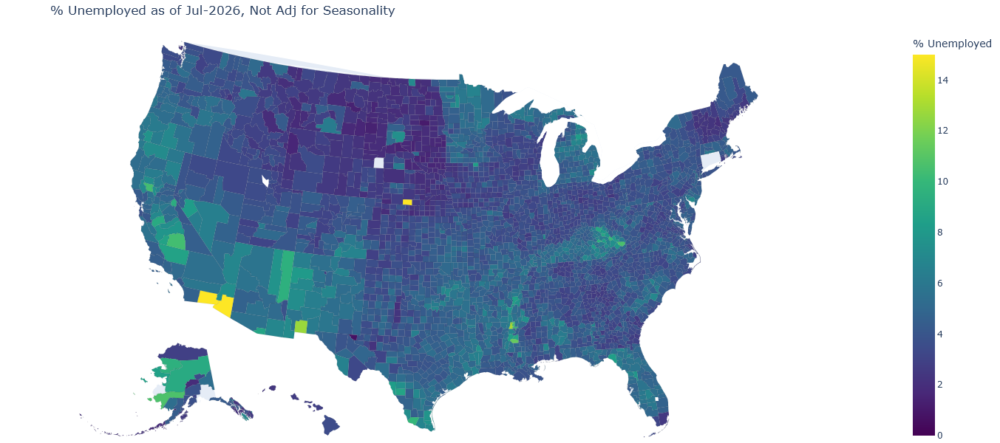

In [9]:
import json
import urllib.request
import plotly.express as px

# County boundaries keyed by 5-digit FIPS
url = "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"
with urllib.request.urlopen(url) as f:
    counties = json.load(f)

fig = px.choropleth(
    df_counties,
    geojson=counties,
    # locations="id",
    locations="fips",
    color="Unemploy-ment Rate (%)",
    color_continuous_scale="Viridis",
    range_color=(0, 15),                # clip outliers so colors stay readable
    scope="usa",                          # Albers USA projection, AK/HI insets
    hover_name="County_Name",
    hover_data={"State_Code": True, "Unemploy-ment Rate (%)": ":.1f"},
    labels={"Unemploy-ment Rate (%)": "% Unemployed"},
    title="% Unemployed as of Jul-2026, Not Adj for Seasonality",
)

fig.update_traces(marker_line_width=0.1)   # thin county borders
fig.update_layout(
    margin=dict(l=0, r=0, t=40, b=0),
    width=1200,
    height=600
)
fig.show()

#### Holoviz Geoviews

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
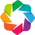

1 counties without data


:Polygons   [Longitude,Latitude]   (NAME,STUSPS,unemployment_rate)

In [8]:
import cartopy.crs as ccrs
import polars as pl
import geopandas as gpd
import geoviews as gv
import holoviews as hv

gv.extension("bokeh")

rates = df_counties.select(
    "fips",
    "County_Name",
    "State_Code",
    unemployment_rate=pl.col("Unemploy-ment Rate (%)"),
)

url = "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_20m.zip"
counties = gpd.read_file(url)
counties = counties[~counties["STATEFP"].isin(["02", "15", "60", "66", "69", "72", "78"])]

gdf = counties.merge(rates.to_pandas(), left_on="GEOID", right_on="fips", how="left")

print(f"{gdf['unemployment_rate'].isna().sum()} counties without data")

plot = gv.Polygons(gdf, vdims=["NAME", "STUSPS", "unemployment_rate"]).opts(
    color="unemployment_rate", cmap="YlOrRd", clim=(0, 10),
    colorbar=True, clabel="Unemployment rate (%)", tools=["hover"],
    projection=ccrs.AlbersEqualArea(
        central_longitude=-96, central_latitude=37.5,
        standard_parallels=(29.5, 45.5),
    ),
    width=1000, height=620, line_width=0.1, line_color="white",
    xaxis=None, yaxis=None, title="US county unemployment rate, Jul-26",
)

# hv.save(plot, "county_unemployment.html")
plot

Another GeoViews version with Alaska and Hawaii added.  Unfortunately, this is more verbose and complex compared to Plotly.

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
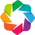

:Polygons   [Longitude,Latitude]   (NAME,STUSPS,unemployment_rate)

In [12]:
import cartopy.crs as ccrs
import geopandas as gpd
import pandas as pd
import geoviews as gv
import holoviews as hv
from shapely import affinity

gv.extension("bokeh")

counties = gpd.read_file("https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_20m.zip")
counties = counties[~counties["STATEFP"].isin(["60", "66", "69", "72", "78"])]  # keep AK and HI this time

def place(part, crs, scale, target_xy):
    """Project to a local CRS, shrink about the centroid, and move it to target_xy (EPSG:5070 meters)."""
    p = part.to_crs(crs)
    c = p.geometry.union_all().centroid          # use .unary_union on geopandas < 1.0
    moved = p.geometry.apply(
        lambda g: affinity.translate(
            affinity.scale(g, xfact=scale, yfact=scale, origin=c),
            xoff=target_xy[0] - c.x, yoff=target_xy[1] - c.y,
        )
    )
    return p.set_geometry(moved).set_crs("EPSG:5070", allow_override=True)

lower48 = counties[~counties["STATEFP"].isin(["02", "15"])].to_crs("EPSG:5070")
alaska  = place(counties[counties["STATEFP"] == "02"], "EPSG:3338",  0.35, (-1.75e6, -0.15e6))
hawaii  = place(counties[counties["STATEFP"] == "15"], "ESRI:102007", 1.0,  (-0.75e6, -0.10e6))

combined = pd.concat([lower48, alaska, hawaii]).to_crs("EPSG:4326")  # GeoViews expects lon/lat input

gdf = combined.merge(rates.to_pandas(), left_on="GEOID", right_on="fips", how="left")

# Same Albers parameters as EPSG:5070, so the insets land where we placed them
albers = ccrs.AlbersEqualArea(
    central_longitude=-96, central_latitude=23, standard_parallels=(29.5, 45.5)
)

plot = gv.Polygons(gdf, vdims=["NAME", "STUSPS", "unemployment_rate"]).opts(
    color="unemployment_rate", cmap="YlOrRd", clim=(0, 10),
    colorbar=True, clabel="Unemployment rate (%)", tools=["hover"],
    projection=albers,
    width=1000, height=620, line_width=0.1, line_color="white",
    xaxis=None, yaxis=None, title="US county unemployment rate, Jul-26",
)

plot